# 04 — Bản nâng cấp (v2)

## 1. Import & Config

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore")

ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
import src.style as S
from src.validation import (purged_walk_forward, classification_metrics, block_bootstrap_auc,
                            three_state_position, backtest, perf_stats)
S.set_theme()
pd.set_option("display.precision", 2)

RAW_DIR       = os.path.join(ROOT, "data", "raw")
PROCESSED_DIR = os.path.join(ROOT, "data", "processed")
FIG_DIR       = os.path.join(ROOT, "reports", "figures")

HORIZONS   = {90: 0.00015, 252: 0.0001}   # threshold giống bản gốc
SPLIT_DATE = "2022-01-01"                 # split cũ, chỉ dùng để kiểm tra lại
WF_START   = "2018-01-01"
STEP       = 63                           # retrain mỗi quý

## 2. Kiểm tra lại pipeline gốc

In [2]:
base  = pd.read_csv(os.path.join(PROCESSED_DIR, "features.csv"), parse_dates=["date"], float_precision="round_trip")
clean = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_dataset.csv"), parse_dates=["date"], float_precision="round_trip")
DROP = ["date","gold","dxy","sp500","oil","vix","usd_vnd","fed_funds","cpi"] + \
       [f"{p}_{h}d" for p in ["slope","target"] for h in HORIZONS]
ORIG_FEATS = [c for c in base.columns if c not in DROP]

# accuracy tốt nhất ở notebook 03 (RF cho 90d, LR cho 252d)
REPORTED_ACC = {90: 78.63, 252: 97.75}

first_test = clean.index[clean["date"] >= SPLIT_DATE][0]
rows = []
for h in HORIZONS:
    t = base[f"target_{h}d"]
    te = t[(base["date"] >= SPLIT_DATE) & t.notna()]
    tr_idx = t[(base["date"] < SPLIT_DATE) & t.notna()].index
    rows.append({
        "horizon": f"{h}d",
        "n_test": len(te),
        "% Up trong test": te.mean() * 100,
        "Acc 'luôn đoán Up'": te.mean() * 100,
        "Acc tốt nhất báo cáo": REPORTED_ACC[h],
        "Số lần đổi nhãn trong test": int((te.diff().abs() > 0).sum()),
        "Mẫu train có nhãn nhìn vào test": int((tr_idx + h > first_test).sum()),
    })
audit = pd.DataFrame(rows).set_index("horizon")
audit

,n_test,% Up trong test,Acc 'luôn đoán Up',Acc tốt nhất báo cáo,Số lần đổi nhãn trong test,Mẫu train có nhãn nhìn vào test
horizon,,,,,,
90d,819,75.58,75.58,78.63,4,89
252d,844,93.84,93.84,97.75,1,194


In [3]:
cpi_mom = clean["cpi"].pct_change() * 100
print(f"% ngày có cpi_mom = 0                    : {(cpi_mom == 0).mean()*100:.1f}%")
print(f"corr(real_rate, fed_funds) trên features : {base['real_rate'].corr(base['fed_funds']):.4f}")

fm = pd.read_csv(os.path.join(RAW_DIR, "fred_monthly.csv"), parse_dates=["date"]).set_index("date")
true_yoy = (fm["CPIAUCSL"].pct_change(12) * 100).reindex(base["date"], method="ffill").values
print(f"cpi_yoy gốc (pct_change 12 dòng)          : trung vị {base['cpi_yoy'].median():.2f}%  "
      f"vs CPI YoY thật: trung vị {np.nanmedian(true_yoy):.2f}%")

d = clean.loc[clean["date"] == "2022-07-01"].iloc[0]
print(f"\nNgày 2022-07-01 dataset đã dùng CPI={d['cpi']} (= CPI tháng 7/2022, công bố 2022-08-10) "
      f"-> look-ahead ~40 ngày")
print(f"Ngày 2022-07-01 dataset đã dùng fed_funds={d['fed_funds']} (= trung bình tháng 7, chỉ biết khi hết tháng)")

% ngày có cpi_mom = 0                    : 95.3%
corr(real_rate, fed_funds) trên features : 0.9991
cpi_yoy gốc (pct_change 12 dòng)          : trung vị 0.00%  vs CPI YoY thật: trung vị 2.17%

Ngày 2022-07-01 dataset đã dùng CPI=294.913 (= CPI tháng 7/2022, công bố 2022-08-10) -> look-ahead ~40 ngày
Ngày 2022-07-01 dataset đã dùng fed_funds=1.68 (= trung bình tháng 7, chỉ biết khi hết tháng)


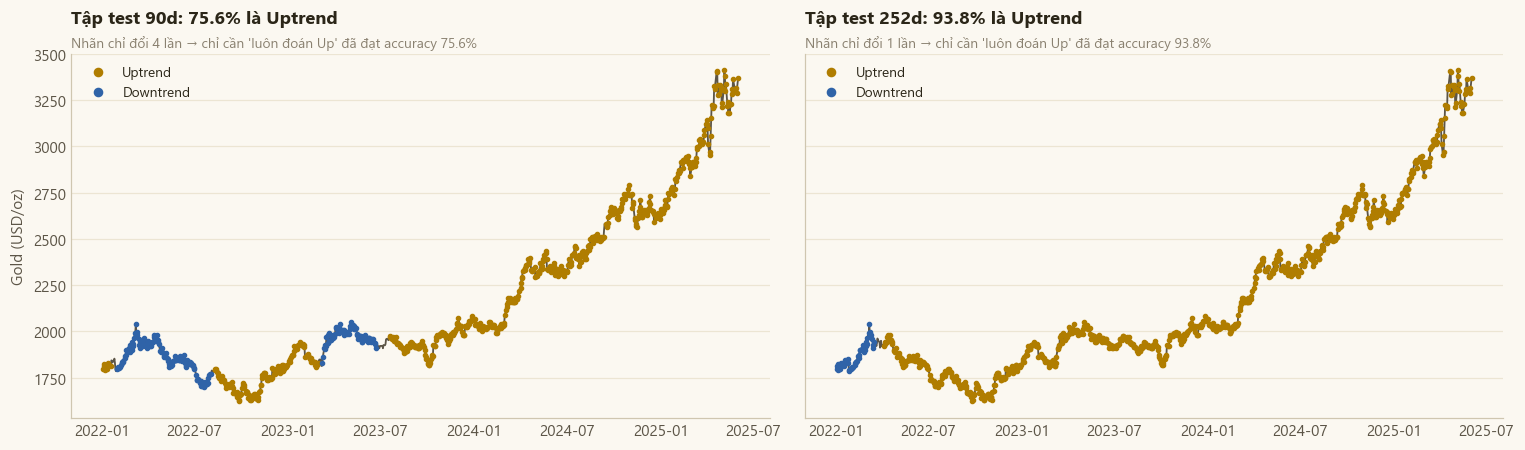

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, h in zip(axes, HORIZONS):
    sub = base[base["date"] >= SPLIT_DATE]
    ax.plot(sub["date"], sub["gold"], color=S.INK_2, lw=1.2, zorder=1)
    for lab, col, name in [(1, S.GOLD, "Uptrend"), (0, S.BLUE, "Downtrend")]:
        m = sub[f"target_{h}d"] == lab
        ax.scatter(sub.loc[m, "date"], sub.loc[m, "gold"], s=7, color=col, label=name, zorder=2)
    up_pct, n_switch = audit.loc[f"{h}d", "% Up trong test"], audit.loc[f"{h}d", "Số lần đổi nhãn trong test"]
    ax.set_title(f"Tập test {h}d: {up_pct:.1f}% là Uptrend")
    S.subtitle(ax, f"Nhãn chỉ đổi {n_switch} lần → chỉ cần 'luôn đoán Up' đã đạt accuracy {up_pct:.1f}%")
    ax.legend(loc="upper left", markerscale=2)
axes[0].set_ylabel("Gold (USD/oz)")
fig.tight_layout()
S.save(fig, "audit_test_labels.png", FIG_DIR)
plt.show()

## 3. Dữ liệu point-in-time

In [5]:
raw = pd.read_csv(os.path.join(RAW_DIR, "raw_dataset.csv"), parse_dates=["date"]).sort_values("date")
mk  = raw[["date", "gold", "dxy", "sp500", "oil", "vix"]].dropna(subset=["gold"]).ffill().reset_index(drop=True)

# số liệu FRED theo ngày thường có vào hôm sau nên lùi 1 ngày
fd = pd.read_csv(os.path.join(RAW_DIR, "fred_daily.csv"), parse_dates=["date"])
fd["date"] += pd.Timedelta(days=1)
fd = fd.set_index("date").ffill().reset_index()   # ngày lễ bị trống

# số liệu tháng: gán theo ngày công bố chứ không theo ngày quan sát
fm = pd.read_csv(os.path.join(RAW_DIR, "fred_monthly.csv"), parse_dates=["date"]).sort_values("date")
fed = fm[["date", "FEDFUNDS"]].dropna().copy()
fed["date"] = fed["date"] + pd.offsets.MonthBegin(1) + pd.Timedelta(days=1)   # là trung bình tháng nên hết tháng mới biết
cpi = fm[["date", "CPIAUCSL"]].dropna().copy()
cpi["cpi_yoy"]    = cpi["CPIAUCSL"].pct_change(12) * 100
cpi["cpi_3m_ann"] = ((cpi["CPIAUCSL"] / cpi["CPIAUCSL"].shift(3)) ** 4 - 1) * 100
cpi["date"] = cpi["date"] + pd.offsets.MonthBegin(1) + pd.Timedelta(days=14)   # CPI ra khoảng giữa tháng sau

ext = pd.read_csv(os.path.join(RAW_DIR, "market_extra.csv"), parse_dates=["date"])
ext = ext.set_index("date").ffill().reset_index()

pit = mk.copy()
for other in [fd, fed, cpi.drop(columns="CPIAUCSL"), ext]:
    pit = pd.merge_asof(pit, other.sort_values("date"), on="date", direction="backward")
print(f"Point-in-time dataset: {pit.shape}  {pit['date'].min().date()} -> {pit['date'].max().date()}")
pit[["date", "gold", "DFII10", "T10YIE", "DGS10", "FEDFUNDS", "cpi_yoy"]].tail(3)

Point-in-time dataset: (3121, 20)  2014-01-02 -> 2026-06-02


,date,gold,DFII10,T10YIE,DGS10,FEDFUNDS,cpi_yoy
3118,2026-05-29,4560.5,2.06,2.39,4.45,3.64,3.95
3119,2026-06-01,4475.2,2.07,2.38,4.45,3.64,3.95
3120,2026-06-02,4537.0,2.07,2.40,4.47,3.63,3.95


corr(Δ252 log gold, Δ252 real yield 10Y) = -0.392


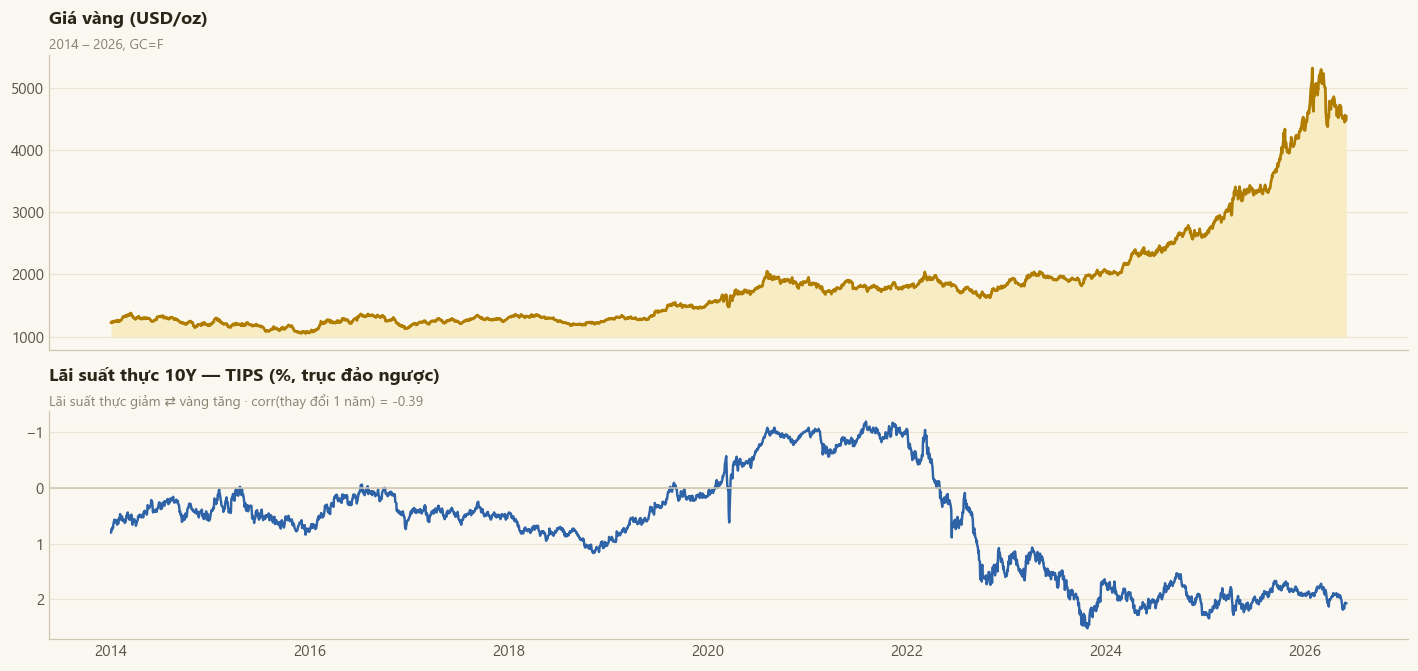

In [6]:
lg = np.log(pit.set_index("date")["gold"])
ry = pit.set_index("date")["DFII10"]
r_252 = lg.diff(252).corr(ry.diff(252))
print(f"corr(Δ252 log gold, Δ252 real yield 10Y) = {r_252:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].fill_between(pit["date"], pit["gold"], pit["gold"].min() * 0.95, color=S.GOLD_PALE, lw=0)
axes[0].plot(pit["date"], pit["gold"], color=S.GOLD, lw=1.8)
axes[0].set_title("Giá vàng (USD/oz)")
S.subtitle(axes[0], "2014 – 2026, GC=F")
axes[1].plot(pit["date"], pit["DFII10"], color=S.BLUE, lw=1.6)
axes[1].axhline(0, color=S.AXIS, lw=1)
axes[1].invert_yaxis()
axes[1].set_title("Lãi suất thực 10Y — TIPS (%, trục đảo ngược)")
S.subtitle(axes[1], f"Lãi suất thực giảm ⇄ vàng tăng · corr(thay đổi 1 năm) = {r_252:.2f}")
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
S.save(fig, "gold_vs_real_yield.png", FIG_DIR)
plt.show()

## 4. Feature engineering v2

In [7]:
def trailing_slope(log_p, w):
    # giống cách tính nhãn nhưng nhìn về quá khứ
    x = np.arange(w, dtype=float)
    k = (x - x.mean()) / ((x - x.mean()) ** 2).sum()
    return log_p.rolling(w).apply(lambda y: np.dot(k, y), raw=True) * 252


def zscore(s, w=252):
    return (s - s.rolling(w).mean()) / s.rolling(w).std()


def build_features_v2(d):
    g, lg = d["gold"], np.log(d["gold"])
    r = lg.diff()
    F = pd.DataFrame({"date": d["date"]})
    # trend
    for w in [21, 63, 126, 252]:
        F[f"tslope_{w}"] = trailing_slope(lg, w)
        F[f"mom_{w}"]    = lg - lg.shift(w)
    F["mom_252_21"]  = lg.shift(21) - lg.shift(252)
    F["tsmom_tstat"] = F["mom_252"] / (r.rolling(252).std() * np.sqrt(252))
    F["ma50_200"]    = np.log(g.rolling(50).mean() / g.rolling(200).mean())
    F["dist_252h"]   = lg - lg.rolling(252).max()
    F["dist_252l"]   = lg - lg.rolling(252).min()
    F["zscore63"]    = (g - g.rolling(63).mean()) / g.rolling(63).std()
    # lãi suất thực, lạm phát
    F["ry10"]        = d["DFII10"]
    F["ry10_chg63"]  = d["DFII10"].diff(63)
    F["ry10_chg252"] = d["DFII10"].diff(252)
    F["ry10_z252"]   = zscore(d["DFII10"])
    F["bei10"]       = d["T10YIE"]
    F["bei10_chg63"] = d["T10YIE"].diff(63)
    F["ny10_chg63"]  = d["DGS10"].diff(63)
    F["fed_funds"]   = d["FEDFUNDS"]
    F["fed_chg252"]  = d["FEDFUNDS"].diff(252)
    F["cpi_yoy"]     = d["cpi_yoy"]
    F["cpi_3m_ann"]  = d["cpi_3m_ann"]
    F["real_ff"]     = d["FEDFUNDS"] - d["cpi_yoy"]
    # dữ liệu thêm, chỉ dùng ở mục 8
    F["gs_ratio_z"]     = zscore(lg - np.log(d["silver"]))
    F["gc_ratio_z"]     = zscore(lg - np.log(d["copper"]))
    F["gc_ratio_chg63"] = (lg - np.log(d["copper"])).diff(63)
    F["silver_mom63"]   = np.log(d["silver"]).diff(63)
    F["copper_mom63"]   = np.log(d["copper"]).diff(63)
    F["gdx_rel63"]      = np.log(d["gdx"]).diff(63) - lg.diff(63)
    F["gdx_rel21"]      = np.log(d["gdx"]).diff(21) - lg.diff(21)
    F["gdx_mom63"]      = np.log(d["gdx"]).diff(63)
    F["curve"]          = d["T10Y2Y"]
    F["curve_chg63"]    = d["T10Y2Y"].diff(63)
    F["epu_log63"]      = np.log(d["USEPUINDXD"].clip(lower=1)).rolling(63).mean()
    F["epu_chg"]        = F["epu_log63"].diff(63)
    F["bdollar_mom63"]  = np.log(d["DTWEXBGS"]).diff(63)
    F["bdollar_mom252"] = np.log(d["DTWEXBGS"]).diff(252)
    F["eur_mom63"]      = np.log(d["eurusd"]).diff(63)
    F["fwd_infl"]       = d["T5YIFR"]
    F["fwd_infl_chg63"] = d["T5YIFR"].diff(63)
    return F


TREND = ["tslope_21", "tslope_63", "tslope_126", "tslope_252", "mom_21", "mom_63", "mom_126", "mom_252",
         "mom_252_21", "tsmom_tstat", "ma50_200", "dist_252h", "dist_252l", "zscore63"]
RATES = ["ry10", "ry10_chg63", "ry10_chg252", "ry10_z252", "bei10", "bei10_chg63", "ny10_chg63",
         "fed_funds", "fed_chg252", "cpi_yoy", "cpi_3m_ann", "real_ff"]
V2_FEATS = TREND + RATES
EXTRA = {
    "Kim loại (bạc, đồng)":       ["gs_ratio_z", "gc_ratio_z", "gc_ratio_chg63", "silver_mom63", "copper_mom63"],
    "Cổ phiếu mỏ vàng (GDX)":     ["gdx_rel63", "gdx_rel21", "gdx_mom63"],
    "Đường cong lợi suất 10Y-2Y": ["curve", "curve_chg63"],
    "Bất định chính sách (EPU)":  ["epu_log63", "epu_chg"],
    "Broad dollar & EUR":         ["bdollar_mom63", "bdollar_mom252", "eur_mom63"],
    "Kỳ vọng lạm phát 5y5y":      ["fwd_infl", "fwd_infl_chg63"],
}

feat_v2 = build_features_v2(pit)

# dùng chung ngày và nhãn với features.csv để so sánh công bằng với bản gốc
D = base.merge(feat_v2.add_prefix("v2__").rename(columns={"v2__date": "date"}), on="date", how="left")
V2 = [f"v2__{c}" for c in V2_FEATS]
EXTRA = {k: [f"v2__{c}" for c in v] for k, v in EXTRA.items()}
D["ret_next"] = np.log(D["gold"].shift(-1) / D["gold"])

print(f"Khung đánh giá: {D.shape}  {D['date'].min().date()} -> {D['date'].max().date()}")
print(f"Đặc trưng v2  : {len(V2)} ({len(TREND)} trend + {len(RATES)} rates)   |   đặc trưng gốc: {len(ORIG_FEATS)}")
print(f"NaN v2 sau 2016: {D.loc[D['date'] >= '2016-01-01', V2].isna().sum().sum()}")

Khung đánh giá: (2869, 94)  2014-01-02 -> 2025-06-02
Đặc trưng v2  : 26 (14 trend + 12 rates)   |   đặc trưng gốc: 37
NaN v2 sau 2016: 0


## 5. Mô hình

In [8]:
# tham số XGBoost tốt nhất ở notebook 03
ORIG_XGB = {
    90:  dict(n_estimators=422, max_depth=3, learning_rate=0.014234695208527307, subsample=0.6029148123346109,
              colsample_bytree=0.5242100717712144, reg_alpha=16.406224249006375, reg_lambda=2.728486555750041,
              min_child_weight=60, gamma=3.1220259036281455),
    252: dict(n_estimators=192, max_depth=2, learning_rate=0.009380341222321733, subsample=0.6520912881377339,
              colsample_bytree=0.6053609135821184, reg_alpha=4.987837577705995, reg_lambda=7.941848380430207,
              min_child_weight=28, gamma=4.314300865357961),
}


class OriginalPipeline:
    # ExtraTrees chọn top 20 rồi XGBoost, nhưng chọn lại trong từng fold
    def __init__(self, h):
        self.h = h
    def fit(self, X, y):
        sel = ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X, y)
        self.cols = np.argsort(-sel.feature_importances_)[:20]
        self.m = XGBClassifier(**ORIG_XGB[self.h], scale_pos_weight=(y == 0).sum() / max((y == 1).sum(), 1),
                               random_state=42, n_jobs=-1, tree_method="hist",
                               objective="binary:logistic", eval_metric="auc")
        self.m.fit(X[:, self.cols], y)
        return self
    def predict_proba(self, X):
        return self.m.predict_proba(X[:, self.cols])


def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000, class_weight="balanced"))


def make_lgbm():
    return LGBMClassifier(n_estimators=300, learning_rate=0.02, num_leaves=7, min_child_samples=80,
                          subsample=0.7, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
                          class_weight="balanced", random_state=42, n_jobs=4, verbose=-1)


class MeanEnsemble:
    def fit(self, X, y):
        self.ms = [make_lr().fit(X, y), make_lgbm().fit(X, y)]
        return self
    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.ms], axis=0)


def momentum_rule(h):
    # đoán Up nếu slope quá khứ đang dương
    s = D["v2__tslope_63" if h == 90 else "v2__tslope_252"]
    return (1 / (1 + np.exp(-5 * s))).rename("p_up")

In [9]:
MODEL_ORDER = ["Always-Up", "Momentum rule", "Gốc (không purge)", "Gốc (purged)",
               "v2 Logistic", "v2 LightGBM", "v2 Ensemble"]
preds = {}
for h in HORIZONS:
    oos = D["date"] >= WF_START
    preds[h] = {
        "Always-Up":         pd.Series(0.5, index=D.index[oos]),
        "Momentum rule":     momentum_rule(h)[oos],
        "Gốc (không purge)": purged_walk_forward(D, ORIG_FEATS, h, lambda: OriginalPipeline(h), WF_START, STEP, purge=False),
        "Gốc (purged)":      purged_walk_forward(D, ORIG_FEATS, h, lambda: OriginalPipeline(h), WF_START, STEP),
        "v2 Logistic":       purged_walk_forward(D, V2, h, make_lr, WF_START, STEP),
        "v2 LightGBM":       purged_walk_forward(D, V2, h, make_lgbm, WF_START, STEP),
        "v2 Ensemble":       purged_walk_forward(D, V2, h, MeanEnsemble, WF_START, STEP),
    }
    print(f"{h}d: xong {len(preds[h])} mô hình")

90d: xong 7 mô hình


252d: xong 7 mô hình


## 6. Kết quả walk-forward 2018 - 2025

In [10]:
def evaluate(h, p):
    lab = D.loc[p.index, f"target_{h}d"]
    m = lab.notna()
    y, pp = lab[m].astype(int).values, p[m].values
    res = classification_metrics(y, pp)
    if np.unique(pp).size > 1:
        lo, hi = block_bootstrap_auc(y, pp)
    else:
        lo = hi = 50.0
    res["AUC 95% CI"] = f"[{lo:.1f}, {hi:.1f}]"
    res["_lo"], res["_hi"], res["n"] = lo, hi, int(m.sum())
    return res


common = {h: sorted(set.intersection(*[set(p.index) for p in preds[h].values()])) for h in HORIZONS}
results = {}
for h in HORIZONS:
    results[h] = pd.DataFrame({k: evaluate(h, preds[h][k].loc[common[h]]) for k in MODEL_ORDER}).T
    print(f"\n=== Horizon {h}d — {results[h]['n'].iloc[0]} mẫu có nhãn, "
          f"{D.loc[common[h], f'target_{h}d'].mean()*100:.1f}% Up ===")
    display(results[h][["AUC", "AUC 95% CI", "Balanced Acc", "Accuracy", "F1 (Up)", "MCC", "Brier"]]
            .astype({"AUC": float, "Balanced Acc": float, "Accuracy": float, "F1 (Up)": float, "MCC": float, "Brier": float}).round(3))

pd.concat({f"{h}d": r.drop(columns=["_lo", "_hi"]) for h, r in results.items()}).to_csv(
    os.path.join(ROOT, "reports", "results_v2_walkforward.csv"))


=== Horizon 90d — 1723 mẫu có nhãn, 67.9% Up ===


,AUC,AUC 95% CI,Balanced Acc,Accuracy,F1 (Up),MCC,Brier
Always-Up,50.00,"[50.0, 50.0]",50.00,67.91,80.89,0.00,0.25
Momentum rule,50.12,"[34.4, 64.2]",49.21,53.63,64.31,-0.01,0.29
Gốc (không purge),68.40,"[53.6, 81.4]",54.95,58.56,68.07,0.10,0.21
Gốc (purged),67.41,"[51.5, 81.5]",55.92,63.38,74.00,0.12,0.22
v2 Logistic,43.06,"[27.7, 63.0]",46.89,53.45,65.55,-0.06,0.37
v2 LightGBM,40.75,"[26.4, 56.6]",46.54,43.59,47.97,-0.07,0.39
v2 Ensemble,42.10,"[26.7, 61.2]",41.12,45.15,56.47,-0.17,0.35



=== Horizon 252d — 1707 mẫu có nhãn, 82.5% Up ===


,AUC,AUC 95% CI,Balanced Acc,Accuracy,F1 (Up),MCC,Brier
Always-Up,50.00,"[50.0, 50.0]",50.00,82.48,90.40,0.00,0.25
Momentum rule,45.23,"[18.1, 72.2]",48.45,63.85,76.71,-0.03,0.22
Gốc (không purge),79.78,"[64.5, 92.9]",66.21,73.81,83.08,0.28,0.15
Gốc (purged),75.57,"[59.7, 89.4]",60.75,70.89,81.22,0.18,0.17
v2 Logistic,74.80,"[58.0, 90.8]",68.34,74.28,83.25,0.31,0.23
v2 LightGBM,80.79,"[66.8, 94.6]",73.64,74.98,83.31,0.38,0.19
v2 Ensemble,78.45,"[63.3, 93.3]",72.43,75.16,83.58,0.37,0.20


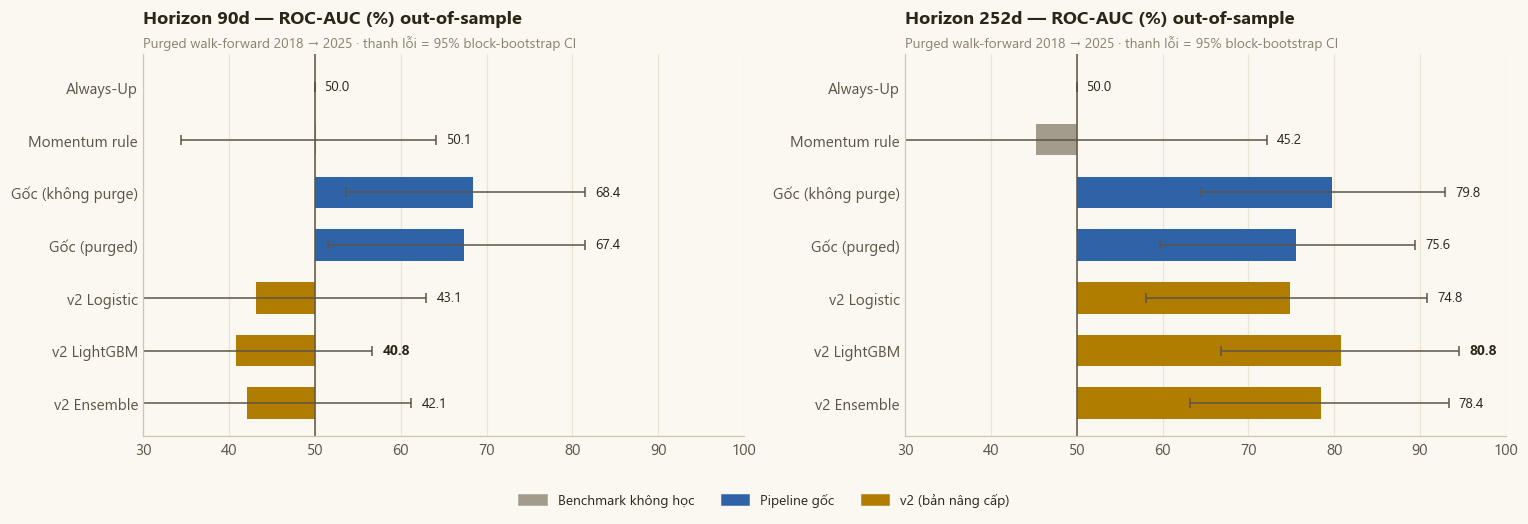

In [11]:
COLOR = {"Always-Up": S.GRAY, "Momentum rule": S.GRAY, "Gốc (không purge)": S.BLUE, "Gốc (purged)": S.BLUE,
         "v2 Logistic": S.GOLD, "v2 LightGBM": S.GOLD, "v2 Ensemble": S.GOLD}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharex=True)
for ax, h in zip(axes, HORIZONS):
    r = results[h].loc[MODEL_ORDER[::-1]]
    y = np.arange(len(r))
    auc = r["AUC"].astype(float).values
    err = np.vstack([auc - r["_lo"].astype(float).values, r["_hi"].astype(float).values - auc])
    ax.barh(y, auc - 50, left=50, height=0.6, color=[COLOR[k] for k in r.index])
    ax.errorbar(auc, y, xerr=err, fmt="none", ecolor=S.INK_2, elinewidth=1, capsize=3)
    for yi, k, a, hi in zip(y, r.index, auc, r["_hi"].astype(float).values):
        ax.text(max(a, hi) + 1.2, yi, f"{a:.1f}", va="center", fontsize=9,
                color=S.INK, fontweight="bold" if k == "v2 LightGBM" else "normal")
    ax.axvline(50, color=S.INK_2, lw=1)
    ax.set_yticks(y, r.index)
    ax.set_xlim(30, 100)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_title(f"Horizon {h}d — ROC-AUC (%) out-of-sample")
    S.subtitle(ax, "Purged walk-forward 2018 → 2025 · thanh lỗi = 95% block-bootstrap CI")
fig.legend(handles=[Patch(color=S.GRAY, label="Benchmark không học"), Patch(color=S.BLUE, label="Pipeline gốc"),
                    Patch(color=S.GOLD, label="v2 (bản nâng cấp)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.05, 1, 1))
S.save(fig, "results_auc.png", FIG_DIR)
plt.show()

## 7. Đổi năm bắt đầu walk-forward

In [12]:
rob = []
for h in HORIZONS:
    for start in ["2017-01-01", "2018-01-01", "2019-01-01", "2020-01-01"]:
        for name, feats, mk in [("Gốc (purged)", ORIG_FEATS, lambda h=h: OriginalPipeline(h)),
                                ("v2 LightGBM", V2, make_lgbm)]:
            if start == WF_START:
                p = preds[h][name]
            else:
                p = purged_walk_forward(D, feats, h, mk, start, STEP)
            r = evaluate(h, p)
            rob.append({"horizon": f"{h}d", "start": start[:4], "model": name,
                        "AUC": r["AUC"], "Balanced Acc": r["Balanced Acc"]})
rob = pd.DataFrame(rob)
rob.pivot_table(index=["horizon", "start"], columns="model", values=["AUC", "Balanced Acc"]).round(1)

AUC             Balanced Acc            
model         Gốc (purged) v2 LightGBM Gốc (purged) v2 LightGBM
horizon start                                                  
252d    2017          74.2        78.8         59.2        70.5
        2018          75.6        81.1         60.7        74.0
        2019          74.5        83.7         63.3        78.0
        2020          84.4        95.5         69.3        85.7
90d     2017          62.0        42.3         51.6        48.8
        2018          67.4        40.3         55.9        46.2
        2019          68.2        48.5         60.1        56.7
        2020          71.5        52.5         60.4        58.9

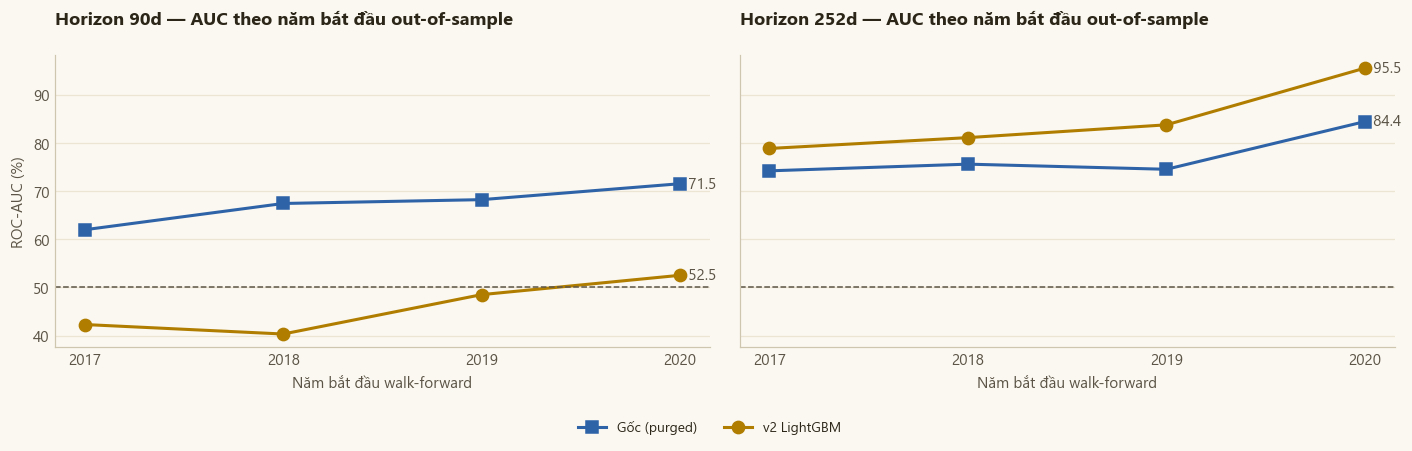

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h in zip(axes, HORIZONS):
    sub = rob[rob["horizon"] == f"{h}d"]
    for name, col, mkr in [("Gốc (purged)", S.BLUE, "s"), ("v2 LightGBM", S.GOLD, "o")]:
        s = sub[sub["model"] == name]
        ax.plot(s["start"], s["AUC"], color=col, marker=mkr, ms=8, label=name)
        ax.text(s["start"].iloc[-1], s["AUC"].iloc[-1], f"  {s['AUC'].iloc[-1]:.1f}", va="center", color=S.INK_2)
    ax.axhline(50, color=S.INK_2, lw=1, ls="--")
    ax.set_title(f"Horizon {h}d — AUC theo năm bắt đầu out-of-sample")
    ax.set_xlabel("Năm bắt đầu walk-forward")
axes[0].set_ylabel("ROC-AUC (%)")
fig.legend(handles=axes[0].get_lines()[:2], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0, 0.06, 1, 1))
S.save(fig, "robustness.png", FIG_DIR)
plt.show()

## 8. Thử thêm dữ liệu

In [14]:
TREND_C = [f"v2__{c}" for c in TREND]
RATES_C = [f"v2__{c}" for c in RATES]
ABL = {"Chỉ trend": TREND_C, "Chỉ lãi suất/lạm phát": RATES_C, "v2 = trend + lãi suất": V2}
ABL |= {f"v2 + {k}": V2 + v for k, v in EXTRA.items()}
ABL |= {"v2 + tất cả dữ liệu bổ sung": V2 + sum(EXTRA.values(), []), "37 đặc trưng gốc": ORIG_FEATS}

abl = []
for h in HORIZONS:
    for name, feats in ABL.items():
        p = preds[h]["v2 LightGBM"] if name == "v2 = trend + lãi suất" else purged_walk_forward(D, feats, h, make_lgbm, WF_START, STEP)
        r = evaluate(h, p)
        abl.append({"horizon": f"{h}d", "Bộ đặc trưng (LightGBM)": name, "n_feat": len(feats),
                    "AUC": r["AUC"], "Balanced Acc": r["Balanced Acc"]})
abl = pd.DataFrame(abl)
abl.pivot_table(index="Bộ đặc trưng (LightGBM)", columns="horizon", values=["AUC", "Balanced Acc"], sort=False).round(1)

AUC       Balanced Acc      
horizon                           90d  252d          90d  252d
Bộ đặc trưng (LightGBM)                                       
Chỉ trend                        31.0  53.9         36.7  48.1
Chỉ lãi suất/lạm phát            44.3  79.0         43.7  67.0
v2 = trend + lãi suất            40.3  81.1         46.2  74.0
v2 + Kim loại (bạc, đồng)        38.2  80.7         41.2  72.8
v2 + Cổ phiếu mỏ vàng (GDX)      41.0  74.9         44.0  74.0
v2 + Đường cong lợi suất 10Y-2Y  37.5  80.5         39.9  74.0
v2 + Bất định chính sách (EPU)   42.9  79.0         49.0  72.5
v2 + Broad dollar & EUR          36.7  80.4         40.7  73.6
v2 + Kỳ vọng lạm phát 5y5y       40.6  80.0         44.6  71.9
v2 + tất cả dữ liệu bổ sung      36.2  73.0         39.6  75.5
37 đặc trưng gốc                 52.6  78.0         50.8  70.2

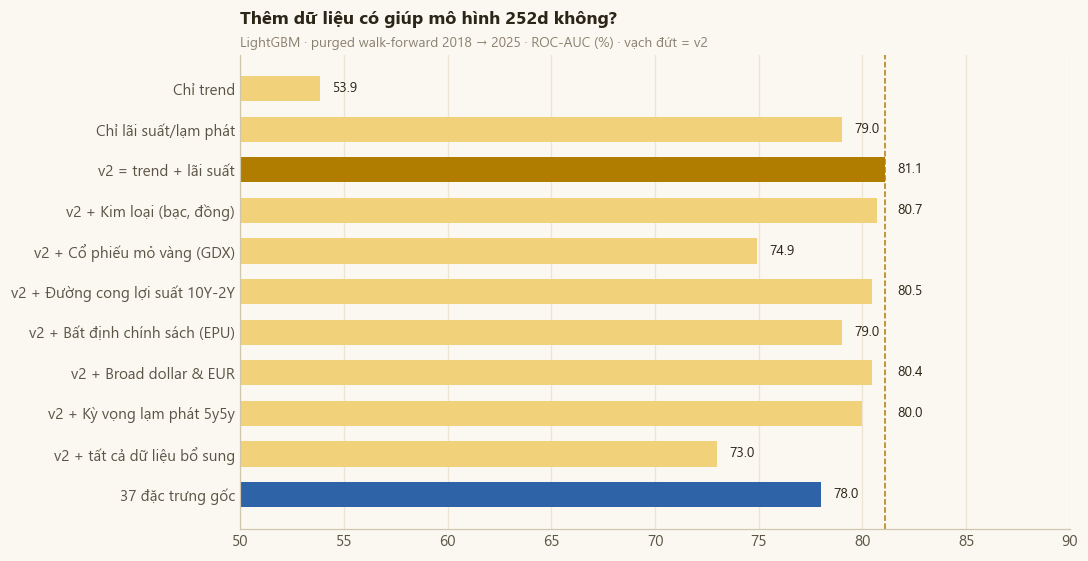

In [15]:
sub = abl[abl["horizon"] == "252d"].iloc[::-1]
ref = sub.loc[sub["Bộ đặc trưng (LightGBM)"] == "v2 = trend + lãi suất", "AUC"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 5.2))
cols = [S.GOLD if n == "v2 = trend + lãi suất" else (S.BLUE if n == "37 đặc trưng gốc" else S.GOLD_LIGHT)
        for n in sub["Bộ đặc trưng (LightGBM)"]]
ax.barh(sub["Bộ đặc trưng (LightGBM)"], sub["AUC"] - 50, left=50, color=cols, height=0.62)
for i, a in enumerate(sub["AUC"]):
    x = ref + 0.6 if ref - 1.5 < a <= ref else a + 0.6
    ax.text(x, i, f"{a:.1f}", va="center", fontsize=9, color=S.INK)
ax.axvline(ref, color=S.GOLD, ls="--", lw=1)
ax.set_xlim(50, 90)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Thêm dữ liệu có giúp mô hình 252d không?")
S.subtitle(ax, "LightGBM · purged walk-forward 2018 → 2025 · ROC-AUC (%) · vạch đứt = v2")
fig.tight_layout()
S.save(fig, "ablation.png", FIG_DIR)
plt.show()

## 9. Mô hình dựa vào gì

Lãi suất / lạm phát    75.8
Trend                  24.2
corr cuộn 2 năm (Δ63 log gold, Δ63 real yield): cuối 2021 = -0.80  |  cuối dữ liệu = -0.25


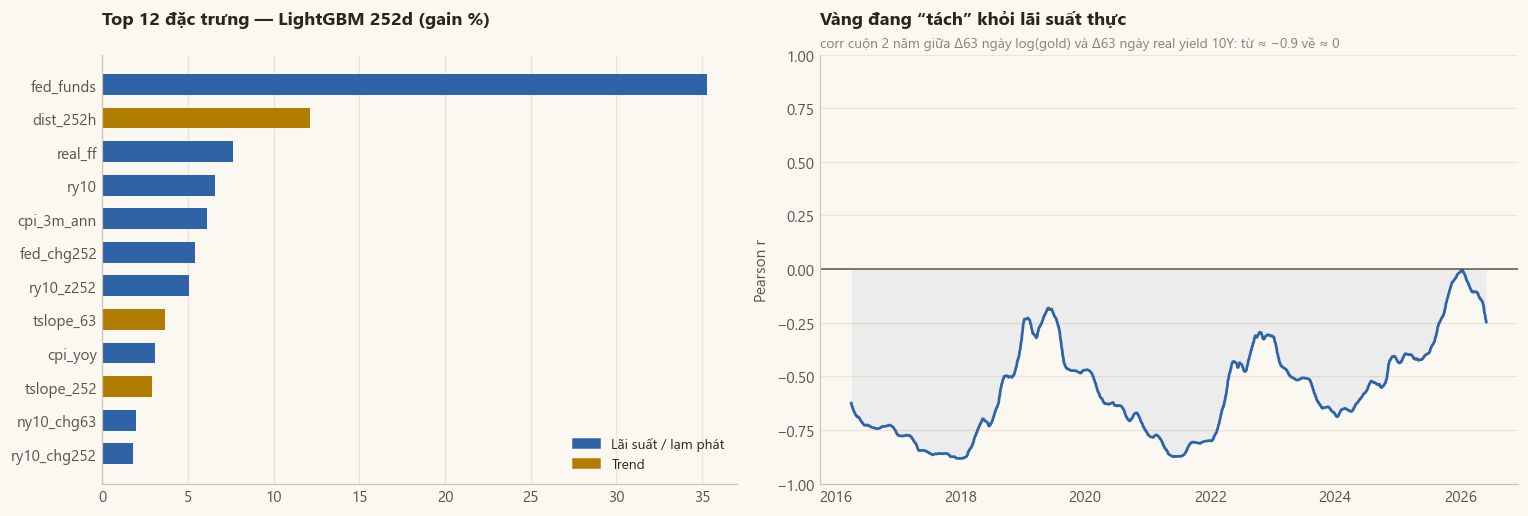

In [16]:
h = 252
lab = D[D[f"target_{h}d"].notna() & D[V2].notna().all(axis=1)]
final = make_lgbm().fit(lab[V2].values, lab[f"target_{h}d"].astype(int).values)
imp = pd.Series(final.booster_.feature_importance("gain"), index=[c.replace("v2__", "") for c in V2])
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
grp = {c: ("Lãi suất / lạm phát" if c in RATES else "Trend") for c in imp.index}
print(imp.groupby(pd.Series(grp)).sum().round(1).to_string())

pi = pit.set_index("date")
rc = np.log(pi["gold"]).diff(63).rolling(504).corr(pi["DFII10"].diff(63))
print(f"corr cuộn 2 năm (Δ63 log gold, Δ63 real yield): cuối 2021 = {rc.loc[:'2021-12-31'].iloc[-1]:.2f}  |  "
      f"cuối dữ liệu = {rc.iloc[-1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
top = imp.head(12)[::-1]
axes[0].barh(top.index, top.values, color=[S.BLUE if grp[c] != "Trend" else S.GOLD for c in top.index], height=0.62)
axes[0].grid(axis="y", visible=False); axes[0].grid(axis="x", visible=True)
axes[0].set_title("Top 12 đặc trưng — LightGBM 252d (gain %)")
axes[0].legend(handles=[Patch(color=S.BLUE, label="Lãi suất / lạm phát"), Patch(color=S.GOLD, label="Trend")], loc="lower right")
axes[1].plot(rc.index, rc, color=S.BLUE, lw=1.8)
axes[1].fill_between(rc.index, rc, 0, color=S.BLUE, alpha=.08, lw=0)
axes[1].axhline(0, color=S.INK_2, lw=1)
axes[1].set_ylim(-1, 1)
axes[1].set_ylabel("Pearson r")
axes[1].set_title("Vàng đang “tách” khỏi lãi suất thực")
S.subtitle(axes[1], "corr cuộn 2 năm giữa Δ63 ngày log(gold) và Δ63 ngày real yield 10Y: từ ≈ −0.9 về ≈ 0")
axes[1].xaxis.set_major_locator(mdates.YearLocator(2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
S.save(fig, "interpretation.png", FIG_DIR)
plt.show()

## 10. Tín hiệu mua/bán và backtest

In [17]:
h = 252
idx = common[h]
ret = D.loc[idx, "ret_next"].fillna(0)
strategies = {
    "Buy & Hold":        pd.Series(1.0, index=idx),
    "Gốc (purged)":      three_state_position(preds[h]["Gốc (purged)"].loc[idx]),
    "v2 LightGBM":       three_state_position(preds[h]["v2 LightGBM"].loc[idx]),
}
bt = {k: backtest(pos, ret, cost_bps=5 if k != "Buy & Hold" else 0) for k, pos in strategies.items()}
perf = pd.DataFrame({k: perf_stats(r) for k, r in bt.items()}).T
perf["% thời gian nắm vàng"] = [strategies[k].mean() * 100 for k in perf.index]
perf["Số lần giao dịch"] = [int(strategies[k].diff().abs().sum()) for k in perf.index]
perf.round(2)

,CAGR %,Vol %,Sharpe,Max DD %,Final x,% thời gian nắm vàng,Số lần giao dịch
Buy & Hold,13.37,15.39,0.89,-20.87,2.50,100.00,0
Gốc (purged),9.82,11.99,0.84,-15.42,1.98,69.02,10
v2 LightGBM,12.86,12.07,1.06,-13.71,2.42,65.98,18


In [18]:
# các đợt vàng giảm hơn 10%, xem mỗi chiến lược lời/lỗ bao nhiêu trong cùng khoảng đó
eq = np.exp(bt["Buy & Hold"].cumsum())
dd = eq / eq.cummax() - 1
episodes, peak = [], dd.index[0]
for i, v in dd.items():
    if v == 0:
        if dd.loc[peak:i].min() < -0.10:
            episodes.append((peak, dd.loc[peak:i].idxmin()))
        peak = i
if dd.loc[peak:].min() < -0.10:
    episodes.append((peak, dd.loc[peak:].idxmin()))
period_ret = lambda k, a, b: (np.exp(bt[k].loc[a:b].iloc[1:].sum()) - 1) * 100
pd.DataFrame([{"Đỉnh": D.loc[a, "date"].date(), "Đáy": D.loc[b, "date"].date(),
               **{f"{k} %": period_ret(k, a, b) for k in strategies}} for a, b in episodes]).round(1)

,Đỉnh,Đáy,Buy & Hold %,Gốc (purged) %,v2 LightGBM %
0,2018-01-24,2018-08-15,-13.7,-13.7,-13.7
1,2020-03-06,2020-03-17,-11.8,0.0,-0.6
2,2020-08-05,2022-09-23,-20.9,-2.6,4.9


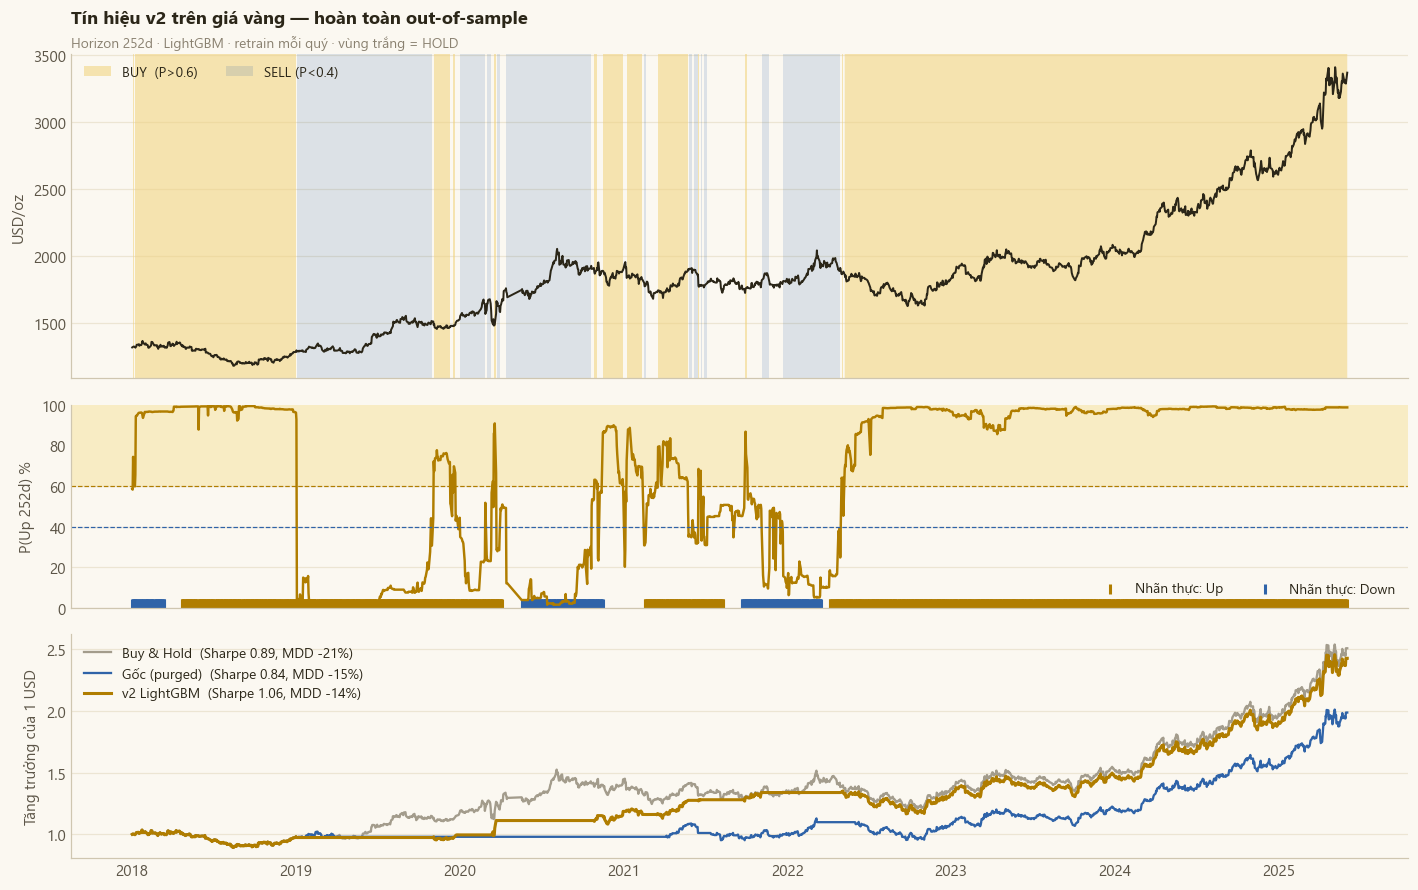

In [19]:
dates = D.loc[idx, "date"].values
p_v2 = preds[h]["v2 LightGBM"].loc[idx].values
gold = D.loc[idx, "gold"].values
y_true = D.loc[idx, f"target_{h}d"].values

fig, axes = plt.subplots(3, 1, figsize=(13, 8.2), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1.1]})
ax = axes[0]
ax.plot(dates, gold, color=S.INK, lw=1.3, zorder=3)
ax.fill_between(dates, gold.min() * .9, gold.max() * 1.05, where=p_v2 > 0.6, color=S.GOLD_LIGHT, alpha=.55, lw=0, label="BUY  (P>0.6)")
ax.fill_between(dates, gold.min() * .9, gold.max() * 1.05, where=p_v2 < 0.4, color=S.BLUE, alpha=.15, lw=0, label="SELL (P<0.4)")
ax.set_ylim(gold.min() * .92, gold.max() * 1.03)
ax.set_title("Tín hiệu v2 trên giá vàng — hoàn toàn out-of-sample")
S.subtitle(ax, "Horizon 252d · LightGBM · retrain mỗi quý · vùng trắng = HOLD")
ax.legend(loc="upper left", ncol=2)
ax.set_ylabel("USD/oz")

ax = axes[1]
ax.plot(dates, p_v2 * 100, color=S.GOLD, lw=1.6)
ax.axhspan(60, 100, color=S.GOLD_PALE, lw=0)
ax.axhline(60, color=S.GOLD, lw=.8, ls="--"); ax.axhline(40, color=S.BLUE, lw=.8, ls="--")
ax.scatter(dates[y_true == 1], np.full((y_true == 1).sum(), 2), marker="|", s=40, color=S.GOLD, label="Nhãn thực: Up")
ax.scatter(dates[y_true == 0], np.full((y_true == 0).sum(), 2), marker="|", s=40, color=S.BLUE, label="Nhãn thực: Down")
ax.set_ylim(0, 100); ax.set_ylabel("P(Up 252d) %")
ax.legend(loc="lower right", ncol=2)

ax = axes[2]
for k, col in [("Buy & Hold", S.GRAY), ("Gốc (purged)", S.BLUE), ("v2 LightGBM", S.GOLD)]:
    eq = np.exp(bt[k].cumsum())
    ax.plot(dates, eq, color=col, lw=2 if k == "v2 LightGBM" else 1.5,
            label=f"{k}  (Sharpe {perf.loc[k, 'Sharpe']:.2f}, MDD {perf.loc[k, 'Max DD %']:.0f}%)")
ax.set_ylabel("Tăng trưởng của 1 USD")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
S.save(fig, "signal_backtest.png", FIG_DIR)
plt.show()

## 11. Hình cho README

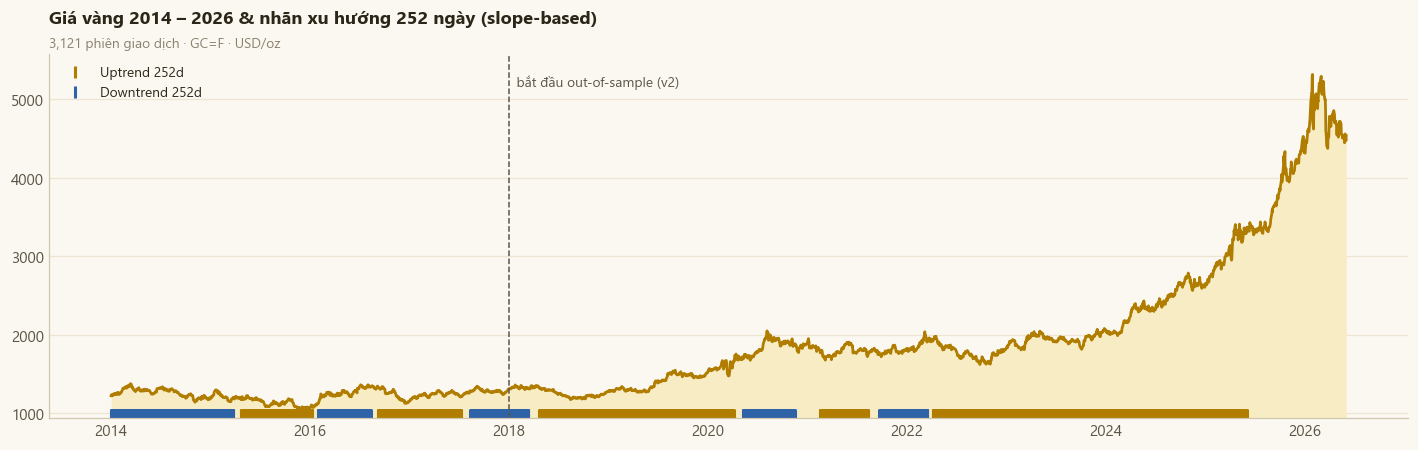

In [20]:
fig, ax = plt.subplots(figsize=(13, 4.2))
c = clean
ax.fill_between(c["date"], c["gold"], c["gold"].min() * .9, color=S.GOLD_PALE, lw=0)
ax.plot(c["date"], c["gold"], color=S.GOLD, lw=1.8)
for lab, col, name in [(1, S.GOLD, "Uptrend 252d"), (0, S.BLUE, "Downtrend 252d")]:
    m = c["target_252d"] == lab
    ax.scatter(c.loc[m, "date"], np.full(m.sum(), c["gold"].min() * .93), marker="|", s=60, color=col, label=name)
ax.axvline(pd.Timestamp(WF_START), color=S.INK_2, lw=1, ls="--")
ax.text(pd.Timestamp(WF_START), c["gold"].max(), "  bắt đầu out-of-sample (v2)", color=S.INK_2, fontsize=9, va="top")
ax.set_ylim(c["gold"].min() * .9, c["gold"].max() * 1.05)
ax.set_title("Giá vàng 2014 – 2026 & nhãn xu hướng 252 ngày (slope-based)")
S.subtitle(ax, f"{len(c):,} phiên giao dịch · GC=F · USD/oz")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
S.save(fig, "hero_gold.png", FIG_DIR)
plt.show()

In [21]:
rep = {"90d": {"Báo cáo gốc (test 2022+)": 76.93, "Gốc — WF không purge": results[90].loc["Gốc (không purge)", "AUC"],
               "Gốc — WF purged": results[90].loc["Gốc (purged)", "AUC"], "v2 LightGBM": results[90].loc["v2 LightGBM", "AUC"]},
       "252d": {"Báo cáo gốc (test 2022+)": 99.73, "Gốc — WF không purge": results[252].loc["Gốc (không purge)", "AUC"],
                "Gốc — WF purged": results[252].loc["Gốc (purged)", "AUC"], "v2 LightGBM": results[252].loc["v2 LightGBM", "AUC"]}}
summary = pd.DataFrame(rep).astype(float).round(1)
summary.loc["Balanced Acc — Gốc purged"] = [results[h].loc["Gốc (purged)", "Balanced Acc"] for h in HORIZONS]
summary.loc["Balanced Acc — v2 LightGBM"] = [results[h].loc["v2 LightGBM", "Balanced Acc"] for h in HORIZONS]
summary.astype(float).round(1)

,90d,252d
Báo cáo gốc (test 2022+),76.9,99.7
Gốc — WF không purge,68.4,79.8
Gốc — WF purged,67.4,75.6
v2 LightGBM,40.8,80.8
Balanced Acc — Gốc purged,55.9,60.7
Balanced Acc — v2 LightGBM,46.5,73.6
